# Disorder-averaged TFIM: unguided and frozen-transformer GFMC


$$
\boxed{H_J=\sum_{\langle ij\rangle}K_{ij}\sigma_i^z\sigma_j^z
-\Gamma\sum_i\sigma_i^x-h\sum_i\sigma_i^z}
$$



$$
K_{ij}=K(1+w u_{ij}),\qquad u_{ij}\overset{\mathrm{iid}}{\sim}\mathcal U[-1,1],
\qquad K=1,\quad w=0.5,\quad K_{ij}\sim\mathcal U[0.5,1.5].
$$


Nearest-neighbor antiferromagnetic bonds on the kagome lattice, with quenched disorder held fixed during each run. Here $J$ labels a bond realization, $Z_i=\sigma_i^z$, $X_i=\sigma_i^x$, and $N=3L^2=12$ with periodic boundaries. The code stores $J_{ij}=-K_{ij}$ because its interaction convention is $-\sum_{\langle ij\rangle}J_{ij}Z_iZ_j$.


$$
\psi_T^{\mathrm{unguided}}(s)=1,\qquad
\psi_T^{\mathrm{guided}}(s)=\sqrt{p_{\theta_*}(s)},\qquad\theta_*\ \mathrm{frozen}.
$$


$$
q=\frac1N\sum_i Z_i^{(a)}Z_i^{(b)},\quad
q_{\rm EA}(J)=\langle q\rangle_J=\frac1N\sum_i\langle Z_i\rangle_J^2,
\quad Q_2(J)=\langle q^2\rangle_J.
$$


$$
\chi_{\rm SG}^{\rm equal\ time}=NQ_2=\frac1N\sum_{ij}\langle Z_iZ_j\rangle_J^2,
\qquad\chi_{\rm conn}^{\rm equal\ time}=\frac1N\sum_{ij}
(\langle Z_iZ_j\rangle_J-\langle Z_i\rangle_J\langle Z_j\rangle_J)^2.
$$


$$
N<\infty,\ h=0,\ \Gamma>0:\quad q_{\rm EA}=0,
\qquad \chi_{\rm conn}=\chi_{\rm SG}.
$$

Equal-time susceptibilities; no imaginary-time response integral. Energy uses the mixed estimator; replica observables use forward walking.

In [1]:
from pathlib import Path
import json
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=Path('/Users/tianyiyan/Dropbox/spin-glasses/data/kagome/transformer_af_disorder_gfmc_v1')
manifest=json.loads((ROOT/'manifest.json').read_text())
status=json.loads((ROOT/'status.json').read_text())
G=manifest['gamma']; F=manifest['h']; IDS=manifest['sample_ids']; SEEDS=manifest['seeds']; N=12
METRICS=['energy','q','q2','chi_sg','chi_connected']
LABELS=[r'$E/N$',r'$q_{\mathrm{EA}}$',r'$\langle q^2\rangle$',r'$\chi_{\mathrm{SG}}$',r'$\chi_{\mathrm{conn}}$']
COLORS={'constant':'#d95f02','network':'#1b78a5'}
NAMES={'constant':'Unguided','network':'Guided'}
exact={}
for p in sorted((ROOT/'cache').glob('*.json')):
 r=json.loads(p.read_text()); r['energy']/=N; r['chi_sg']=N*r['q2']; exact[(r['h'],r['gamma'],r['sample_id'])]=r
pop=defaultdict(list)
raw=[]
for p in sorted((ROOT/'populations').glob('*.json')):
 r=json.loads(p.read_text()); raw.append(r)
 pop[(r['setting'],r['h'],r['gamma'],r['sample_id'],r['guide'])].append(r)
groups={}
for k,rs in pop.items():
 if len(rs)!=len(SEEDS): continue
 assert sorted(r['seed'] for r in rs)==SEEDS
 rs=sorted(rs,key=lambda r:r['seed'])
 a=np.array([[r['energy']/N,r['q'],r['q2'],N*r['q2'],r['chi_connected']] for r in rs])
 groups[k]={'mean':a.mean(0),'mc_se':a.std(0,ddof=1)/np.sqrt(len(rs)),
            'ess':min(min(r['descendant_ess']) for r in rs),
            'bad_cycles':np.mean([np.array(r['descendant_ess'])<8 for r in rs]),
            'seconds':sum(r['seconds'] for r in rs),'replicates':a}
def aligned(setting,h,g,kinds=('constant','network'),ids=IDS):
 return [s for s in ids if (h,g,s) in exact and all((setting,h,g,s,k) in groups for k in kinds)]
def data(setting,h,g,kind,ids):
 return np.array([groups[(setting,h,g,s,kind)]['mean'] for s in ids])
def truth(h,g,ids): return np.array([[exact[(h,g,s)][m] for m in METRICS] for s in ids])
def se(a): return a.std(axis=0,ddof=1)/np.sqrt(len(a)) if len(a)>1 else np.full(a.shape[1:],np.nan)
def save(fig,name):
 fig.savefig(ROOT/(name+'.png'),dpi=180,bbox_inches='tight'); plt.show()
plt.rcParams.update({'font.size':10,'axes.grid':True,'grid.alpha':.2})
complete=status['state']=='completed'
display(Markdown(f"**{status['state']}: {status.get('completed',len(raw)):,} / {status.get('expected',7168):,} populations.** "
                 f"$L=2$, planned $D={len(IDS)}$, $R={len(SEEDS)}$; h = 0, 0.3. Frozen seed501, SHA-256 `{manifest['checkpoint_sha256']}`."))


**completed: 7,168 / 7,168 populations.** $L=2$, planned $D=32$, $R=4$; h = 0, 0.3. Frozen seed501, SHA-256 `5f9fa33b04102ddff2e43179440514021090ed3aaf228ce67dce53c2139e2544`.

$$
W=2048,\quad \tau_{\mathrm{eq}}=32,\quad \tau_E=8,\quad
\tau_{\mathrm{FW}}=8,\quad C=16,\quad \Delta\tau_{\mathrm{branch}}=0.1.
$$


$$
\begin{aligned}
\widehat O_{J,m}&=\frac1R\sum_{r=1}^R\widehat O_{J,m,r},\qquad R=4,\\[4pt]
[\widehat O_m]_D&=\frac1D\sum_{J=1}^D\widehat O_{J,m},\qquad D=32,\\[4pt]
\operatorname{SE}([\widehat O_m]_D)&=\frac{\operatorname{sd}_J(\widehat O_{J,m})}{\sqrt D}.
\end{aligned}
$$

Disorder error bars condition on the four population streams. Seed labels are shared across disorders and methods; the separate Monte Carlo uncertainty uses whole-disorder averages per seed.

$$
\mathcal C_{ij}=\langle Z_iZ_j\rangle_J-\langle Z_i\rangle_J\langle Z_j\rangle_J,
\qquad \langle d_id_j\rangle_J=\mathcal C_{ij}^2,
$$


$$
d_i=\tfrac12(Z_i^{(a)}-Z_i^{(b)})(Z_i^{(c)}-Z_i^{(d)}).
$$

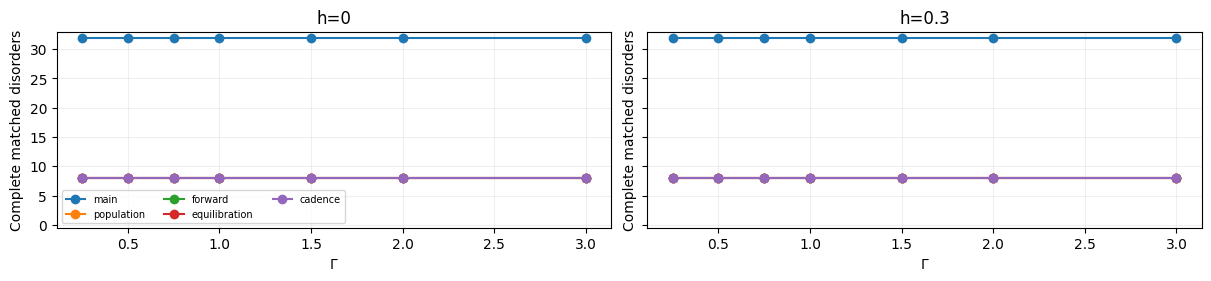

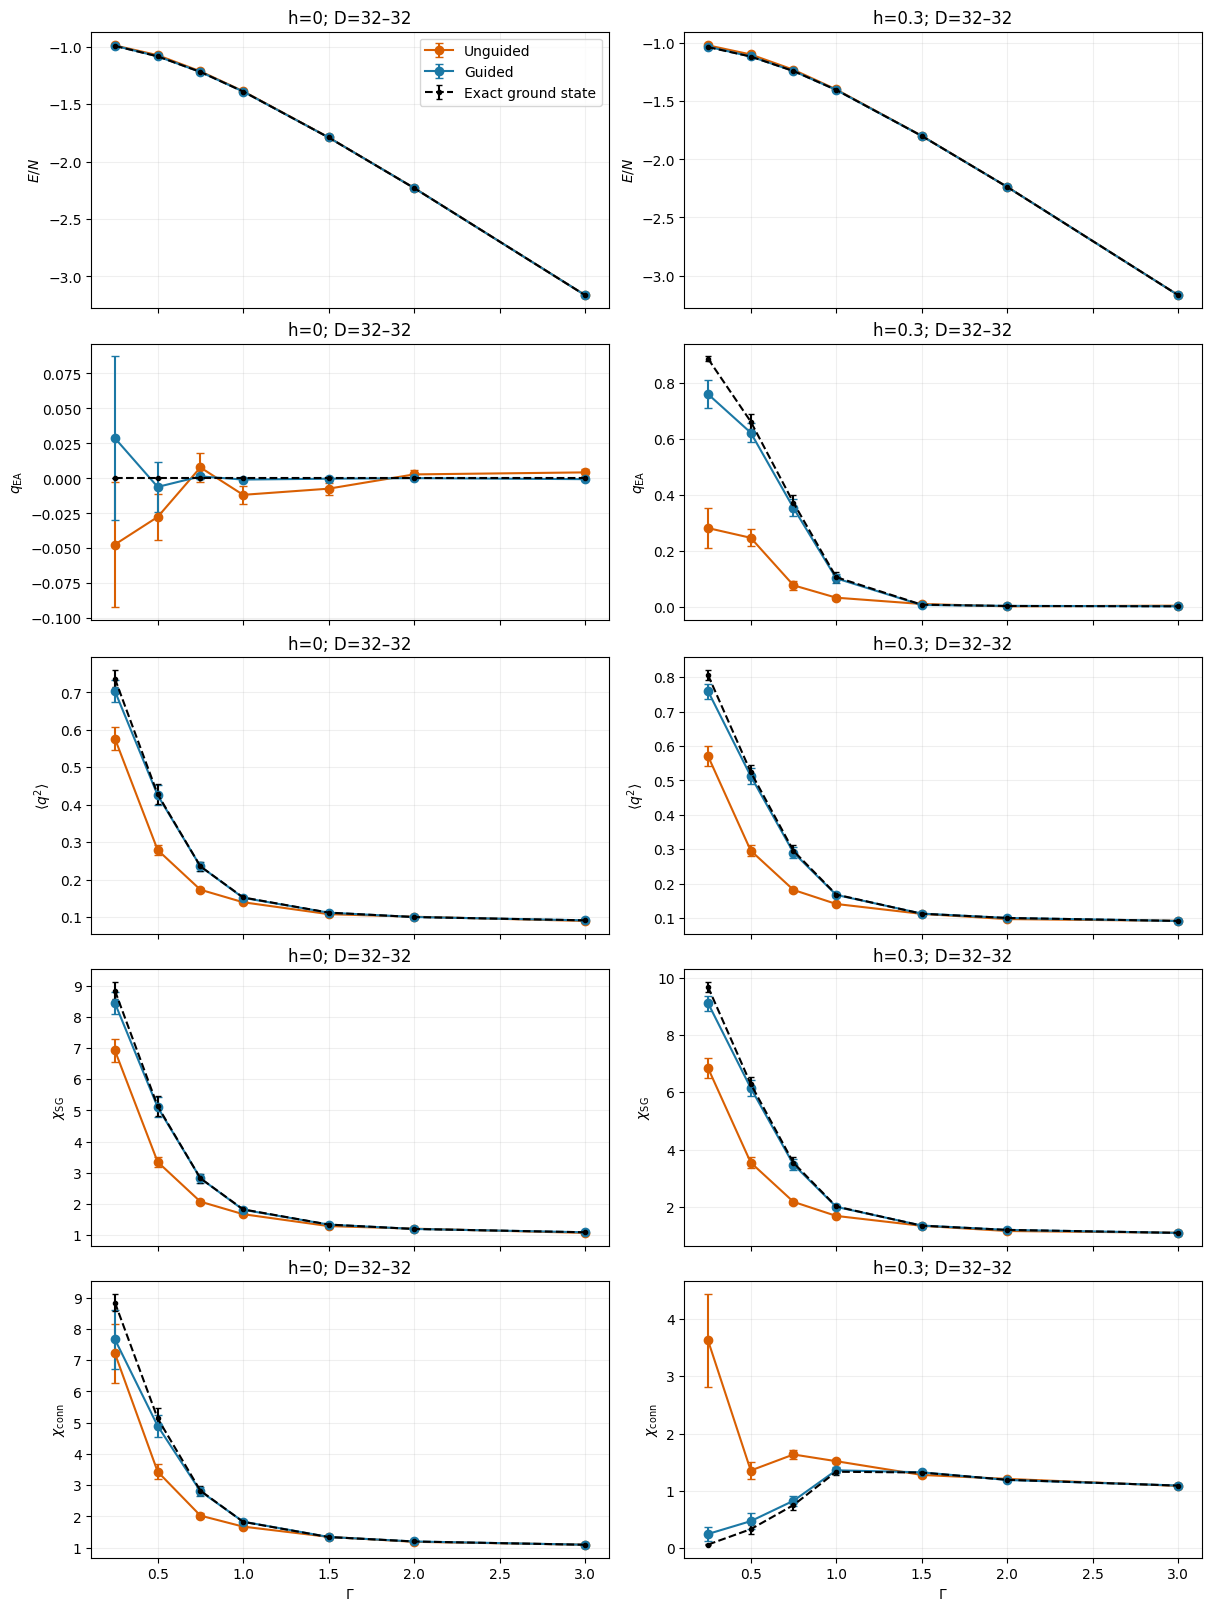

In [2]:
fig,axes=plt.subplots(1,2,figsize=(12,2.7),sharey=True,constrained_layout=True)
for col,h in enumerate(F):
 for setting in manifest['settings']:
  counts=[len(aligned(setting,h,g,ids=IDS if setting=='main' else manifest['audit_ids'])) for g in G]
  axes[col].plot(G,counts,'o-',label=setting)
 axes[col].set(xlabel=r'$\Gamma$',ylabel='Complete matched disorders',title=f'h={h:g}',ylim=(-.5,33))
axes[0].legend(ncol=3,fontsize=7); save(fig,'disorder_coverage')
fig,axes=plt.subplots(5,2,figsize=(12,16),sharex=True,constrained_layout=True)
for col,h in enumerate(F):
 for mi in range(5):
  ax=axes[mi,col]
  counts=[]
  for kind in COLORS:
   x=[]; y=[]; err=[]
   for g in G:
    ids=aligned('main',h,g); counts.append(len(ids))
    if not ids: continue
    a=data('main',h,g,kind,ids); x.append(g); y.append(a.mean(0)[mi]); err.append(se(a)[mi])
   ax.errorbar(x,y,yerr=err,fmt='o-',color=COLORS[kind],label=NAMES[kind],capsize=3)
  means=[]; errors=[]; x=[]
  for g in G:
   ids=aligned('main',h,g)
   if not ids: continue
   a=truth(h,g,ids); x.append(g); means.append(a.mean(0)[mi]); errors.append(se(a)[mi])
  ax.errorbar(x,means,yerr=errors,fmt='k.--',label='Exact ground state',capsize=2)
  nonzero=[d for d in counts if d]
  ax.set(ylabel=LABELS[mi],title=f'h={h:g}; D={min(nonzero) if nonzero else 0}–{max(counts) if counts else 0}')
  if not nonzero: ax.text(.5,.5,'Populations pending',ha='center',transform=ax.transAxes)
  if mi==4: ax.set_xlabel('$\Gamma$')
axes[0,0].legend()
save(fig,'disorder_observables')


$$
\delta O_{J,m}=\widehat O_{J,m}-O_{J,0},\qquad
[\delta O_m]_D=\frac1D\sum_J\delta O_{J,m},\qquad
\mathrm{RMSE}_m=\sqrt{\frac1D\sum_J(\delta O_{J,m})^2}.
$$

RMSE includes stochastic error and bias. Error bars below use matched disorder differences from exact values.

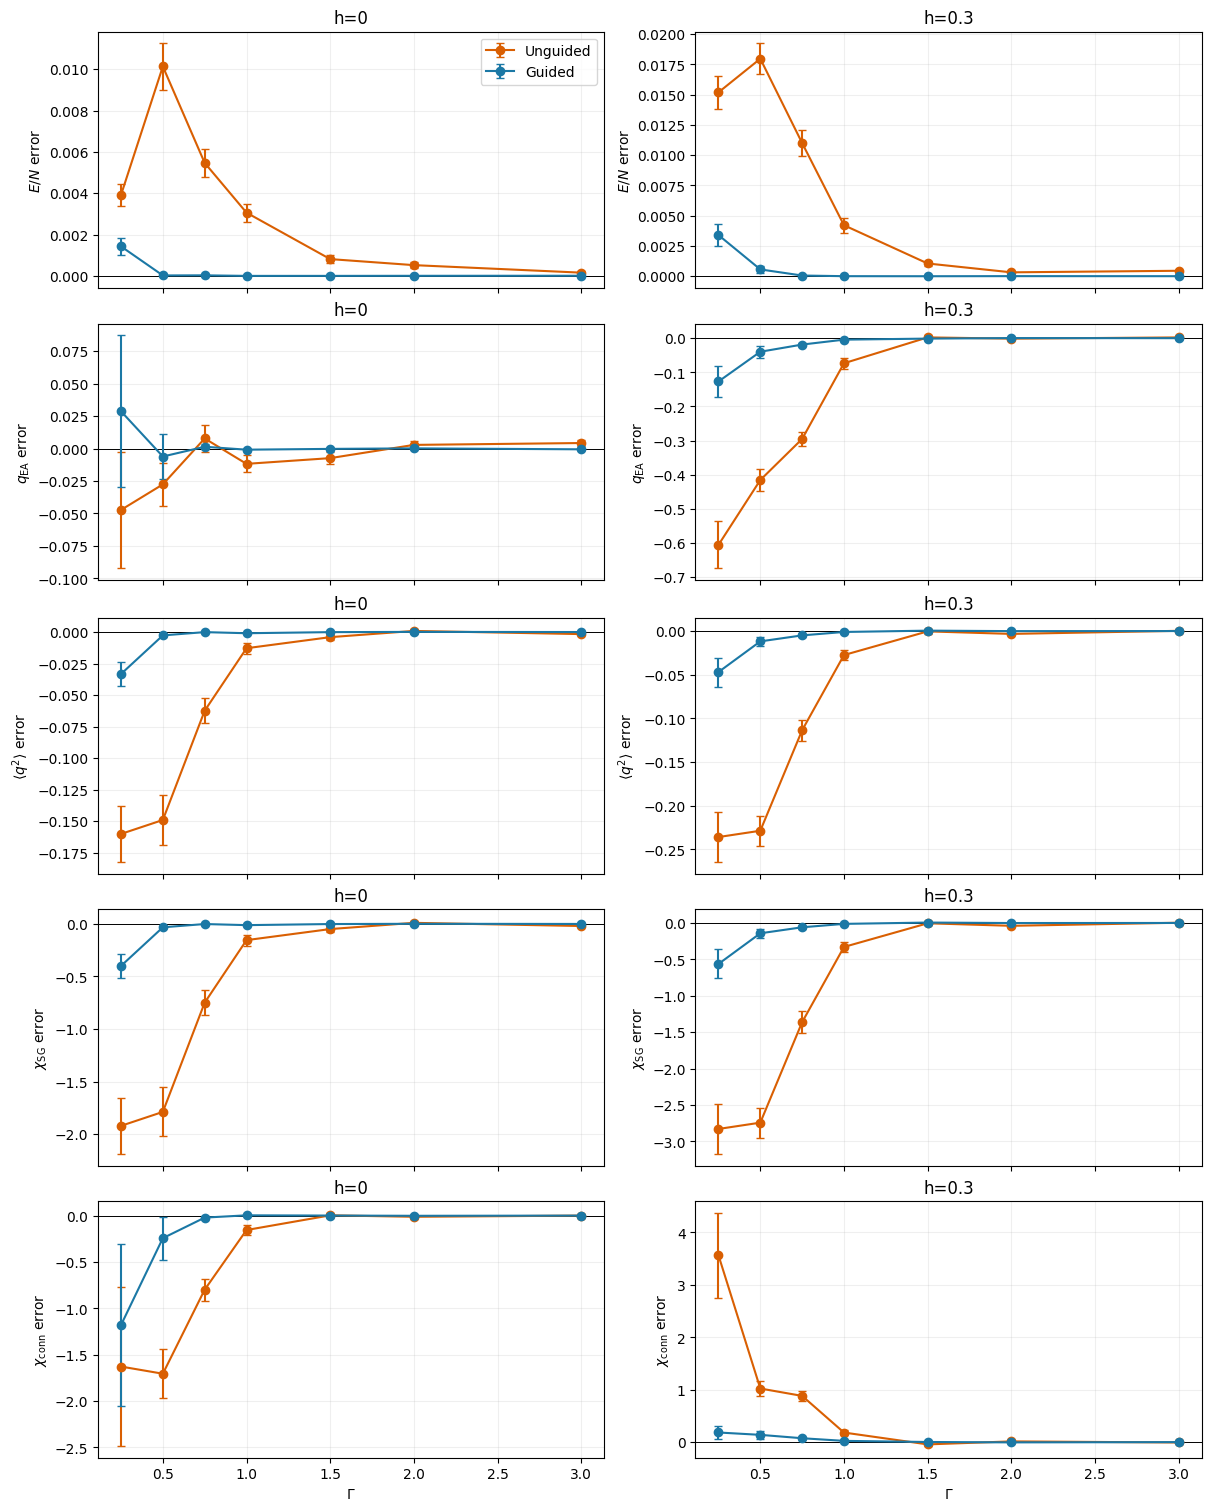

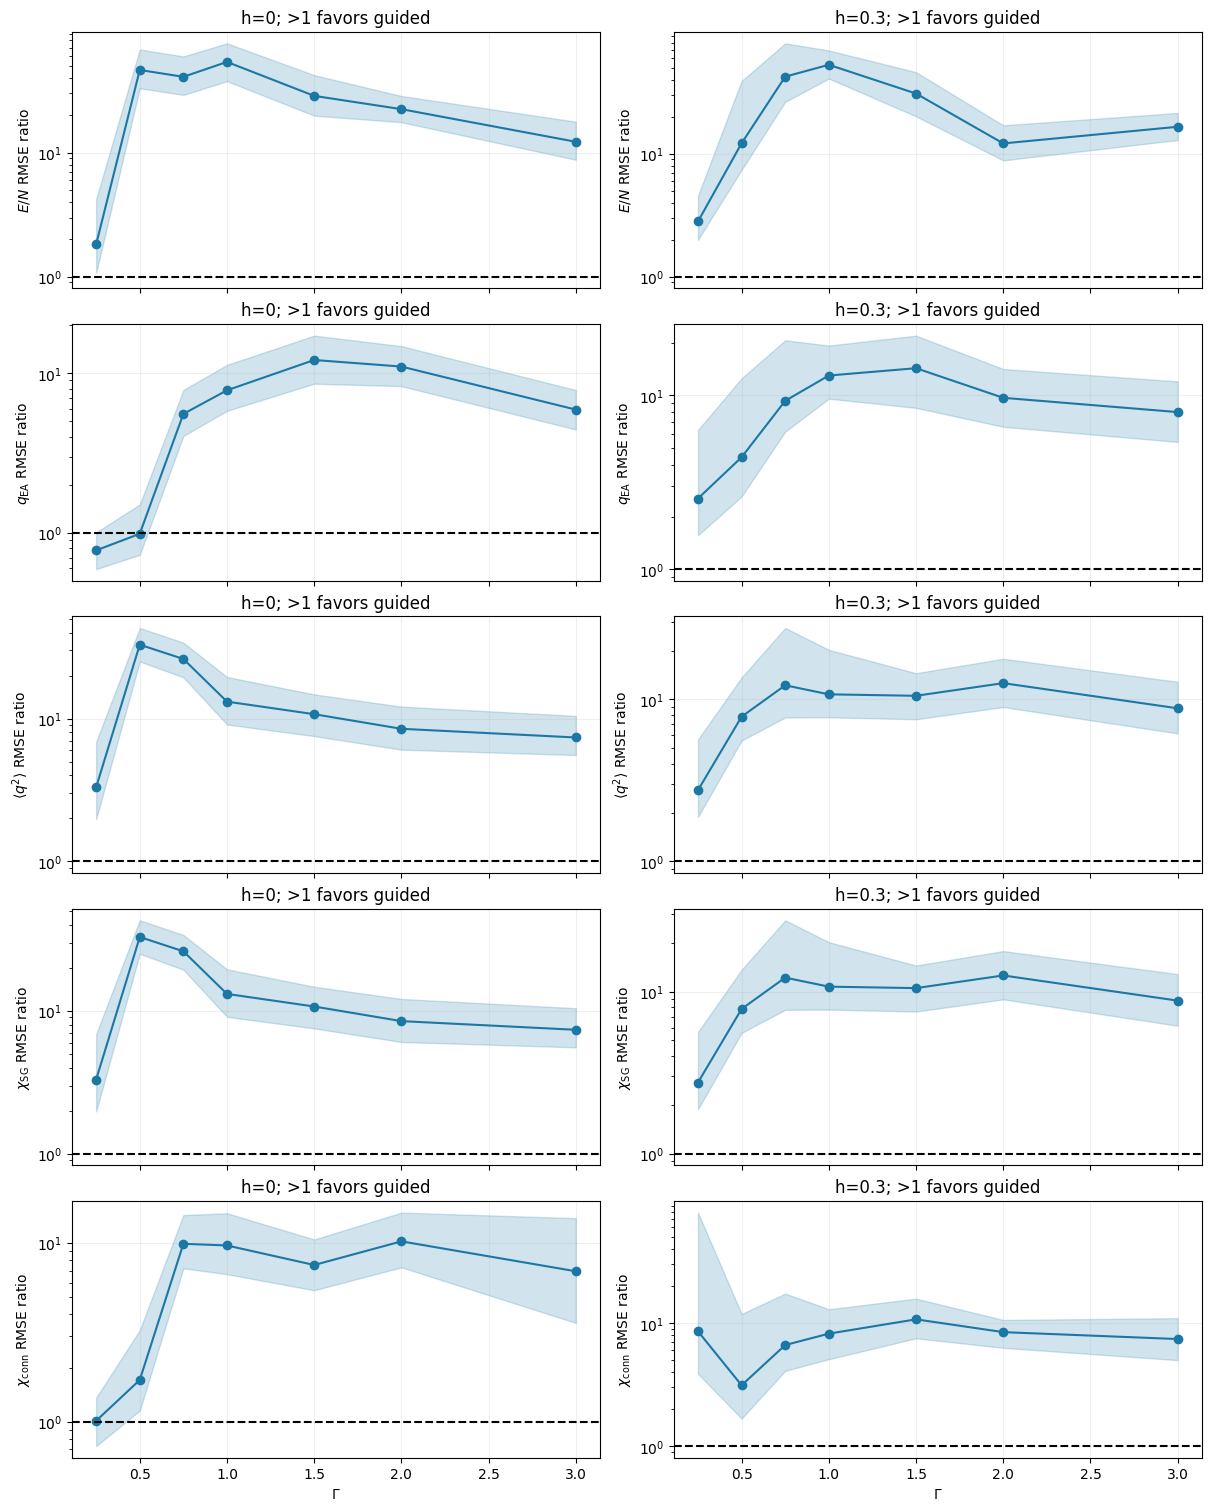

18969

In [3]:
fig,axes=plt.subplots(5,2,figsize=(12,15),sharex=True,constrained_layout=True)
for col,h in enumerate(F):
 for mi in range(5):
  ax=axes[mi,col]; ax.axhline(0,color='k',lw=.7)
  for kind in COLORS:
   x=[]; y=[]; err=[]
   for g in G:
    ids=aligned('main',h,g)
    if not ids: continue
    delta=data('main',h,g,kind,ids)-truth(h,g,ids)
    x.append(g); y.append(delta.mean(0)[mi]); err.append(se(delta)[mi])
   ax.errorbar(x,y,yerr=err,fmt='o-',color=COLORS[kind],label=NAMES[kind],capsize=3)
  ax.set(ylabel=LABELS[mi]+' error',title=f'h={h:g}')
  if mi==4: ax.set_xlabel('$\Gamma$')
axes[0,0].legend(); save(fig,'disorder_exact_errors')
fig,axes=plt.subplots(5,2,figsize=(12,15),sharex=True,constrained_layout=True)
rng=np.random.default_rng(90731)
bootstrap=rng.integers(0,len(IDS),size=(2000,len(IDS)))
improvement=[]
for col,h in enumerate(F):
 for mi in range(5):
  ax=axes[mi,col]; x=[]; ratio=[]; lower=[]; upper=[]
  for g in G:
   ids=aligned('main',h,g)
   if not ids: continue
   t=truth(h,g,ids)
   u=(data('main',h,g,'constant',ids)-t)[:,mi]**2
   v=(data('main',h,g,'network',ids)-t)[:,mi]**2
   index=bootstrap if len(ids)==len(IDS) else np.random.default_rng(90731).integers(len(ids),size=(2000,len(ids)))
   ratio.append(np.sqrt(u.mean()/max(v.mean(),1e-30)))
   boot=np.sqrt(u[index].mean(1)/np.maximum(v[index].mean(1),1e-30))
   lo,hi=np.quantile(boot,[.025,.975]); lower.append(lo); upper.append(hi); x.append(g)
   improvement.append(dict(h=h,gamma=g,disorders=len(ids),observable=METRICS[mi],rmse_ratio=ratio[-1],low=lo,high=hi,
                           unguided_rmse=float(np.sqrt(u.mean())),guided_rmse=float(np.sqrt(v.mean()))))
  ax.plot(x,ratio,'o-',color=COLORS['network']); ax.fill_between(x,lower,upper,alpha=.2,color=COLORS['network'])
  ax.axhline(1,color='k',ls='--'); ax.set_yscale('log')
  ax.set(ylabel=LABELS[mi]+' RMSE ratio',title=f'h={h:g}; >1 favors guided')
  if mi==4: ax.set_xlabel('$\Gamma$')
save(fig,'disorder_improvement')
(ROOT/'improvement.json').write_text(json.dumps(improvement,indent=2)+'\n')


$$
\mathcal I_O=\frac{\mathrm{RMSE}_{\rm unguided}}{\mathrm{RMSE}_{\rm guided}},\qquad
\mathcal I_O>1\ \Longrightarrow\ \text{smaller measured error with guidance}.
$$

Bands: 95% paired disorder bootstrap intervals. Identical disorder resamples are used across fields, observables, and methods.


$$
W:\ 2048\to8192,\quad \tau_{\rm FW}:8\to16,\quad
\tau_{\rm eq}:32\to64,\quad \Delta\tau_{\rm branch}:0.1\to0.05.
$$

Convergence checks use the same first eight disorders. Each setting changes one parameter.

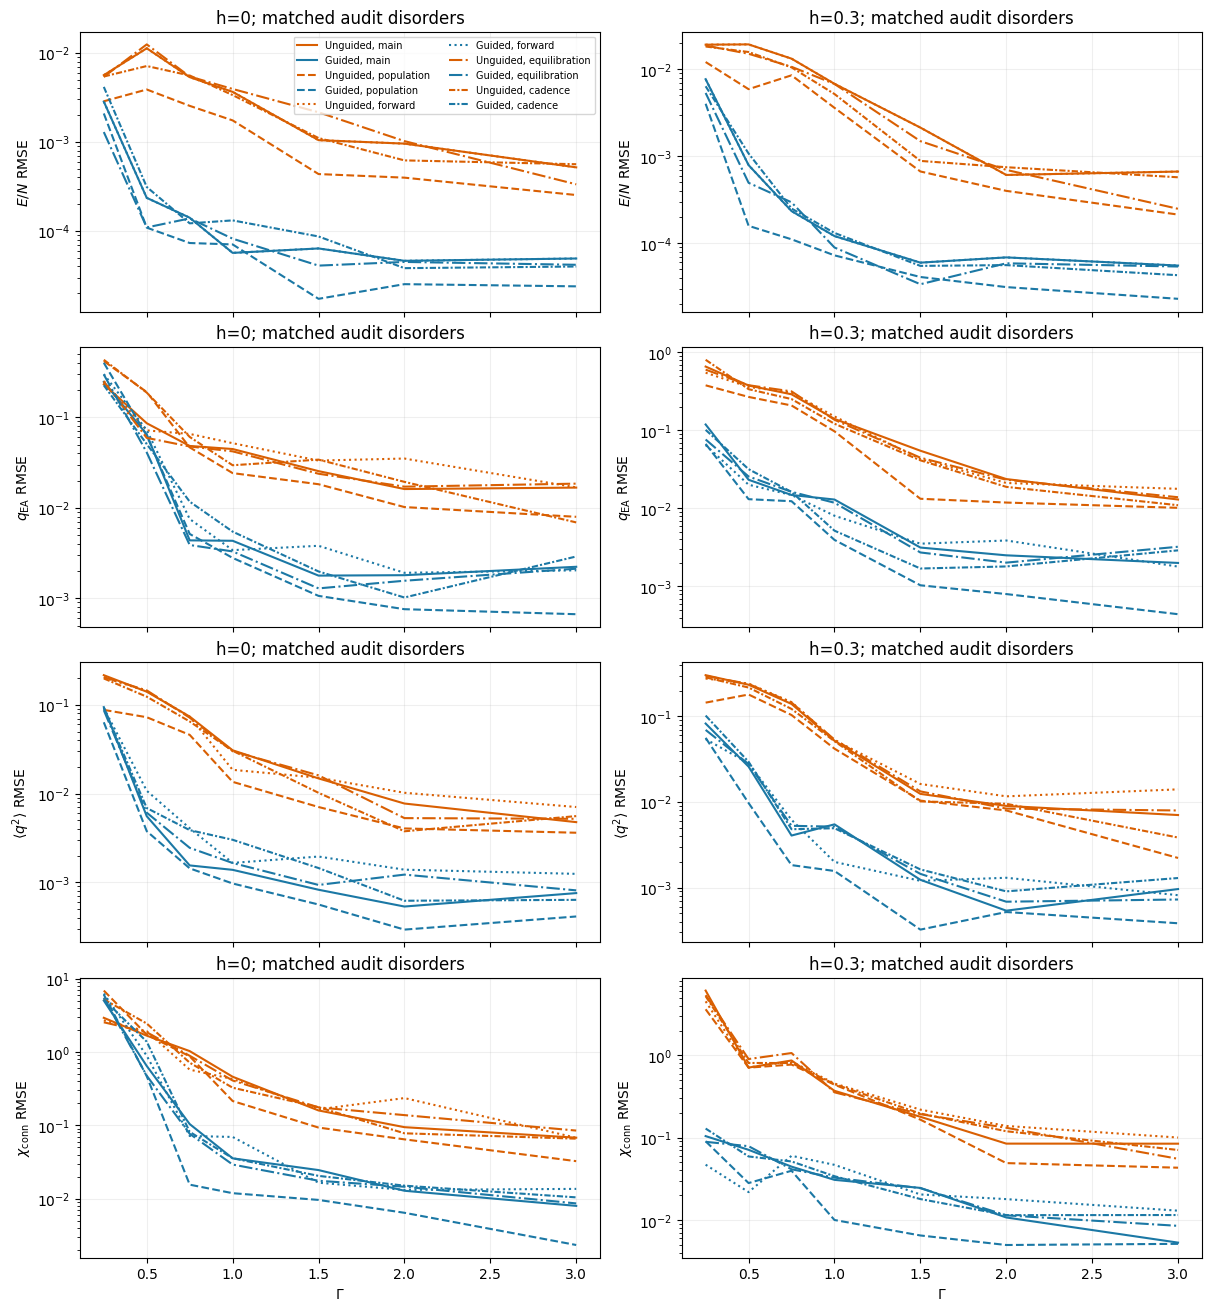

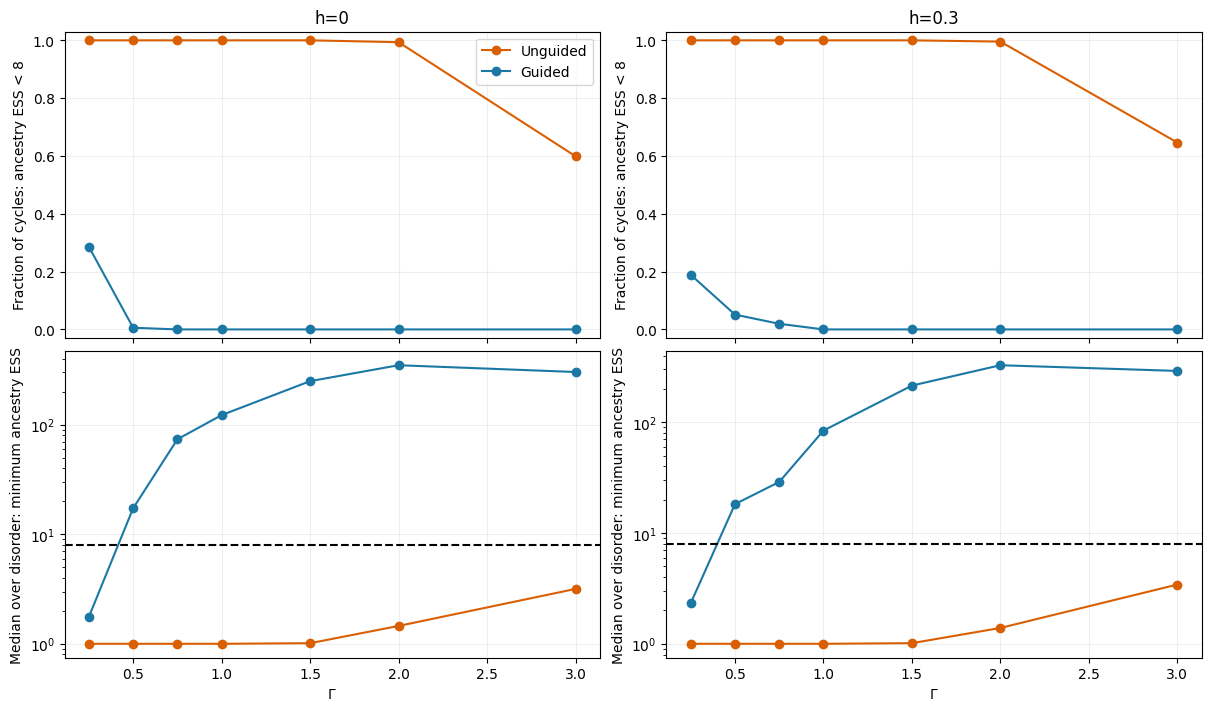

In [4]:
settings=list(manifest['settings'])
fig,axes=plt.subplots(4,2,figsize=(12,13),sharex=True,constrained_layout=True)
style={'main':'-','population':'--','forward':':','equilibration':'-.','cadence':(0,(3,1,1,1))}
for col,h in enumerate(F):
 for row,mi in enumerate([0,1,2,4]):
  ax=axes[row,col]
  for setting in settings:
   for kind in COLORS:
    x=[]; y=[]
    for g in G:
     ids=[s for s in manifest['audit_ids'] if all((st,h,g,s,k) in groups for st in settings for k in COLORS)]
     if not ids: continue
     delta=data(setting,h,g,kind,ids)-truth(h,g,ids)
     x.append(g); y.append(np.sqrt(np.mean(delta[:,mi]**2)))
    ax.plot(x,y,color=COLORS[kind],ls=style[setting],label=f'{NAMES[kind]}, {setting}')
  ax.set(ylabel=LABELS[mi]+' RMSE',title=f'h={h:g}; matched audit disorders')
  ax.set_yscale('log')
  if row==3: ax.set_xlabel('$\Gamma$')
axes[0,0].legend(fontsize=7,ncol=2); save(fig,'disorder_convergence')
fig,axes=plt.subplots(2,2,figsize=(12,7),sharex=True,constrained_layout=True)
for col,h in enumerate(F):
 for kind in COLORS:
  x=[]; bad=[]; ess=[]
  for g in G:
   ids=aligned('main',h,g)
   if not ids: continue
   x.append(g); bad.append(np.mean([groups[('main',h,g,s,kind)]['bad_cycles'] for s in ids]))
   ess.append(np.median([groups[('main',h,g,s,kind)]['ess'] for s in ids]))
  axes[0,col].plot(x,bad,'o-',color=COLORS[kind],label=NAMES[kind])
  axes[1,col].semilogy(x,ess,'o-',color=COLORS[kind])
 axes[0,col].set(title=f'h={h:g}',ylabel='Fraction of cycles: ancestry ESS < 8',ylim=(-.03,1.03))
 axes[1,col].set(xlabel='$\Gamma$',ylabel='Median over disorder: minimum ancestry ESS')
 axes[1,col].axhline(8,color='k',ls='--')
axes[0,0].legend(); save(fig,'disorder_ancestry')


$$
[O]_d=\frac1d\sum_{J=1}^{d}\widehat O_J,\qquad d\in\{4,8,16,32\},\qquad
\overline O_r=\frac1D\sum_J\widehat O_{J,r},\qquad
\operatorname{SE}_{\rm MC}([O]_D)=\frac{\operatorname{sd}_r(\overline O_r)}{\sqrt R}.
$$

Disorder accumulation is a precision check; population and projection stability are assessed separately above.

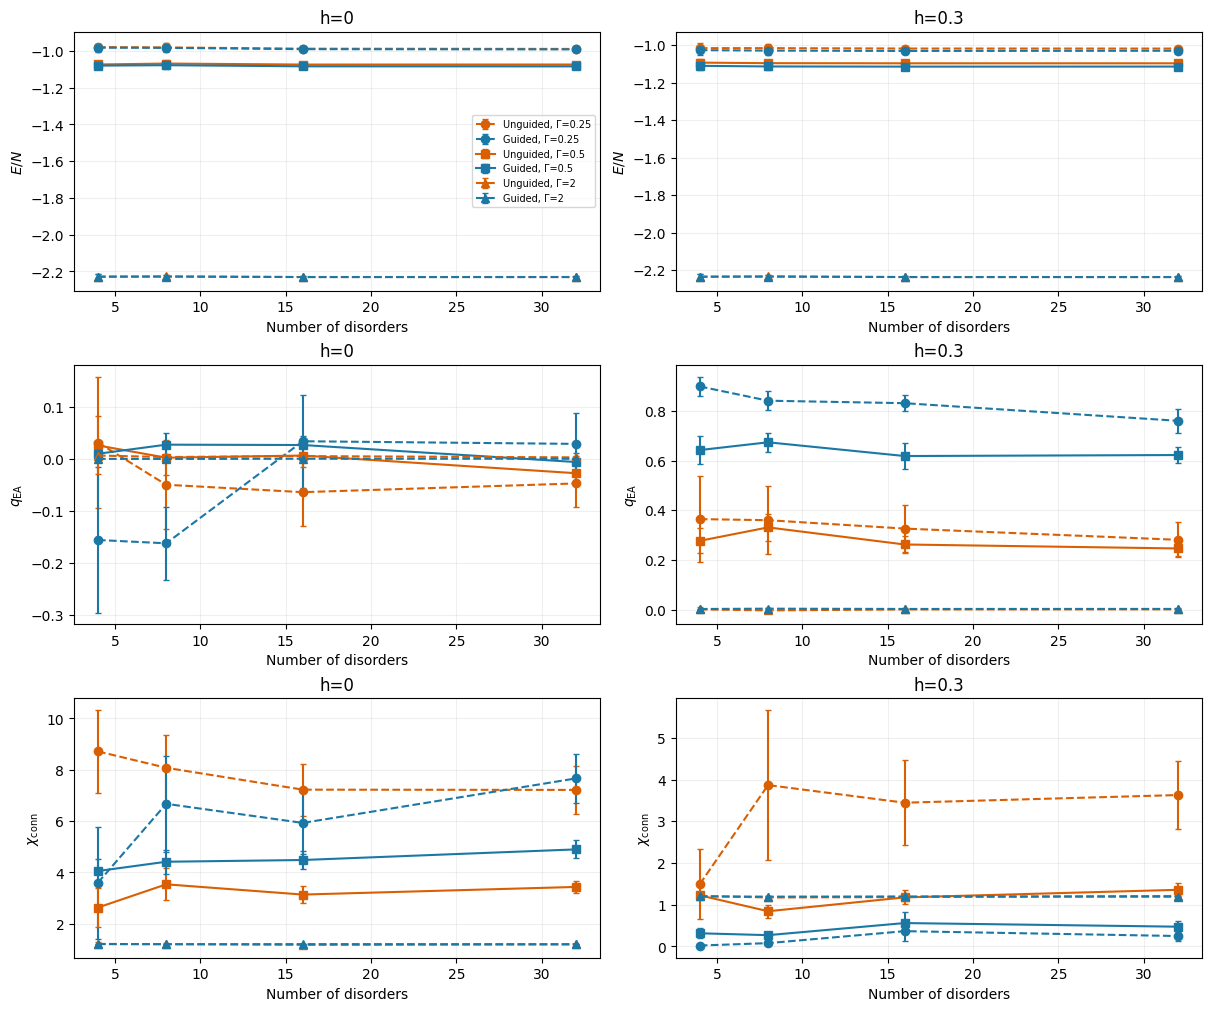

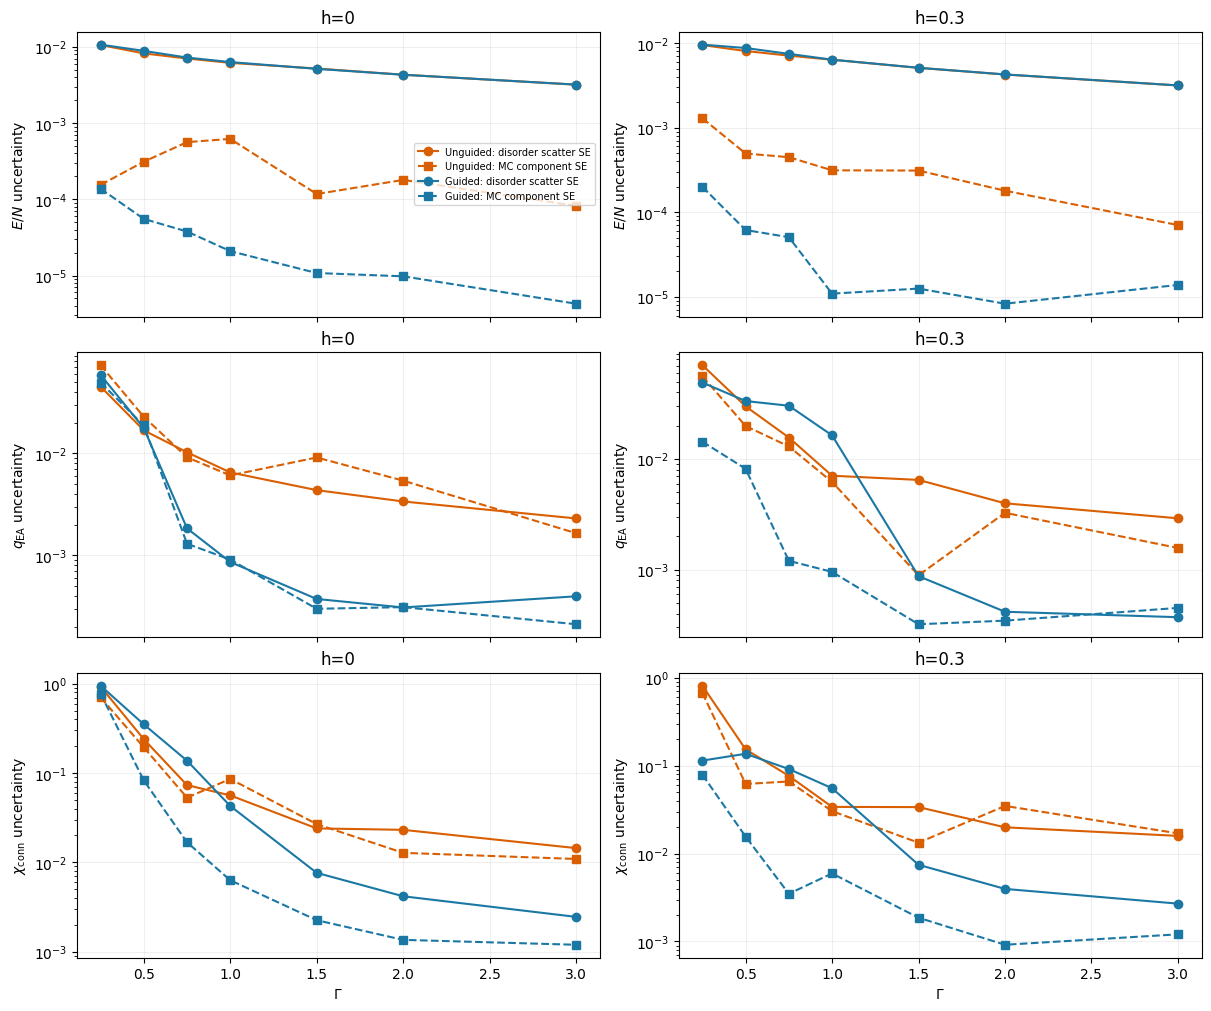

In [5]:
fig,axes=plt.subplots(3,2,figsize=(12,10),constrained_layout=True)
for col,h in enumerate(F):
 for row,mi in enumerate([0,1,4]):
  ax=axes[row,col]
  for g,marker in [(.25,'o'),(.5,'s'),(2.,'^')]:
   for kind in COLORS:
    x=[]; y=[]; e=[]
    ids=aligned('main',h,g)
    for d in [4,8,16,32]:
     if len(ids)<d: continue
     a=data('main',h,g,kind,ids[:d]); x.append(d); y.append(a.mean(0)[mi]); e.append(se(a)[mi])
    ax.errorbar(x,y,yerr=e,marker=marker,color=COLORS[kind],ls='-' if g==.5 else '--',label=f'{NAMES[kind]}, Γ={g:g}',capsize=2)
  ax.set(xlabel='Number of disorders',ylabel=LABELS[mi],title=f'h={h:g}')
axes[0,0].legend(fontsize=7); save(fig,'disorder_accumulation')
fig,axes=plt.subplots(3,2,figsize=(12,10),sharex=True,constrained_layout=True)
for col,h in enumerate(F):
 for row,mi in enumerate([0,1,4]):
  ax=axes[row,col]
  for kind in COLORS:
   x=[]; total=[]; mc=[]
   for g in G:
    ids=aligned('main',h,g)
    if len(ids)<2: continue
    a=data('main',h,g,kind,ids); x.append(g); total.append(se(a)[mi])
    replicate_means=np.mean([groups[('main',h,g,s,kind)]['replicates'][:,mi] for s in ids],axis=0)
    mc.append(replicate_means.std(ddof=1)/np.sqrt(len(SEEDS)))
   ax.semilogy(x,total,'o-',color=COLORS[kind],label=NAMES[kind]+': disorder scatter SE')
   ax.semilogy(x,mc,'s--',color=COLORS[kind],label=NAMES[kind]+': MC component SE')
  ax.set(ylabel=LABELS[mi]+' uncertainty',title=f'h={h:g}')
  if row==2: ax.set_xlabel('$\Gamma$')
axes[0,0].legend(fontsize=7); save(fig,'disorder_uncertainty')


$$
\phi_t=e^{-t(H-E_0)}\psi_T,\qquad
P_{t,f}^{(\infty)}(s)=\frac{\phi_t(s)\phi_f(s)}{\sum_{s'}\phi_t(s')\phi_f(s')}.
$$


$$
\widehat O-O_0=\underbrace{\widehat O-O_{t,f}^{(\infty)}}_{\text{population and sampling}}
+\underbrace{O_{t,f}^{(\infty)}-O_0}_{\text{finite projection time}}.
$$

Exact finite-forward targets average the same sixteen tag times as production. RMSE component magnitudes do not add: the squared total also contains their cross term. “Population and sampling” includes branching-cadence effects.

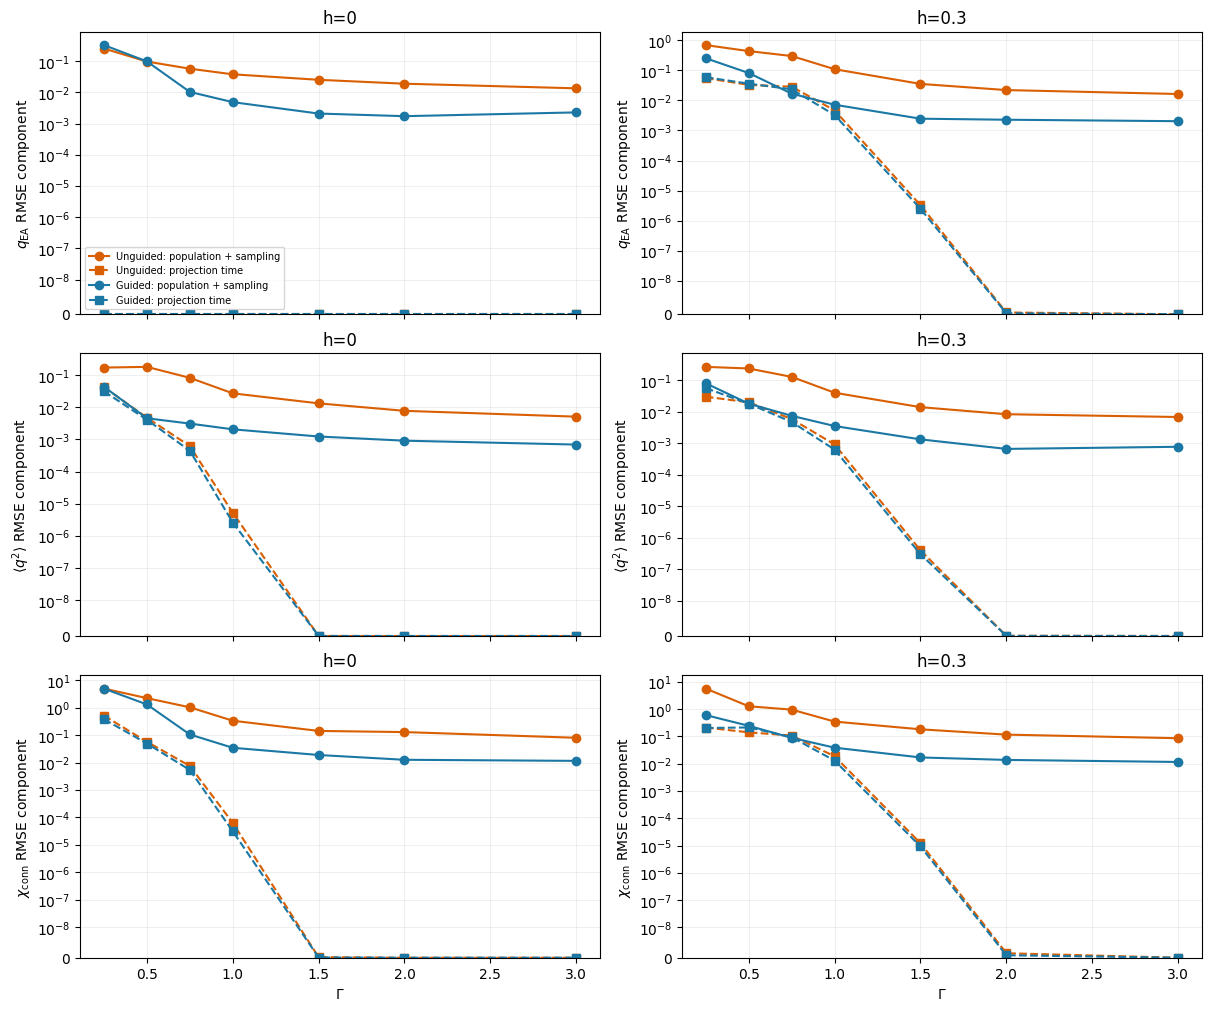

Finite-forward references: 448 / 448 contexts.

In [6]:
finite={}
for p in sorted((ROOT/'finite_forward').glob('*.json')):
 r=json.loads(p.read_text())
 for row in r['rows']:
  finite[(row['setting'],r['h'],r['gamma'],r['sample_id'],row['guide'])]=row['mean']
fig,axes=plt.subplots(3,2,figsize=(12,10),sharex=True,constrained_layout=True)
for col,h in enumerate(F):
 for row,mi in enumerate([1,2,4]):
  ax=axes[row,col]
  available=False
  for kind in COLORS:
   x=[]; population=[]; projection=[]
   for g in G:
    ids=[s for s in aligned('main',h,g) if all(('main',h,g,s,k) in finite for k in COLORS)]
    if not ids: continue
    available=True
    target=np.array([finite[('main',h,g,s,kind)][METRICS[mi]] for s in ids])
    measured=data('main',h,g,kind,ids)[:,mi]; exact_values=truth(h,g,ids)[:,mi]
    x.append(g); population.append(np.sqrt(np.mean((measured-target)**2)))
    projection.append(np.sqrt(np.mean((target-exact_values)**2)))
   ax.plot(x,population,'o-',color=COLORS[kind],label=NAMES[kind]+': population + sampling')
   ax.plot(x,projection,'s--',color=COLORS[kind],label=NAMES[kind]+': projection time')
  ax.set(ylabel=LABELS[mi]+' RMSE component',title=f'h={h:g}')
  ax.set_yscale('symlog',linthresh=1e-8); ax.set_ylim(bottom=0)
  if not available: ax.text(.5,.5,'Matched populations / references pending',ha='center',transform=ax.transAxes)
  if row==2: ax.set_xlabel(r'$\Gamma$')
axes[0,0].legend(fontsize=7); save(fig,'disorder_bias_sources')
display(Markdown(f"Finite-forward references: {len(list((ROOT/'finite_forward').glob('*.json')))} / 448 contexts."))


$$
\text{Scope: }N=12,\ D=32,\ R=4.\qquad
\text{Frozen neural amplitudes are cached; propagation cost excludes neural preparation.}
$$

Finite-size comparison with exact references. Ancestry loss and unresolved parameter dependence remain visible; no thermodynamic phase boundary or larger-system speedup is inferred.